ERA5 Wind Speed Dataset

In [7]:
# Cell 1 - ERA5 Wind Speed Dataset (Kaggle)

from pathlib import Path
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import MinMaxScaler

# 1. Kaggle paths
experiment_dir = Path("/kaggle/working")
results_dir = experiment_dir / "era5_wind_e4000"
results_dir.mkdir(parents=True, exist_ok=True)

# 2. Find uploaded files
data_files = list(
    Path("/kaggle/input").rglob("era5_wind_10sites.pt")
)

model_files = list(
    Path("/kaggle/input").rglob("02_climate_model.ipynb")
)

if len(data_files) != 1:
    raise FileNotFoundError(
        f"Expected one ERA5 dataset, found: {data_files}"
    )

if len(model_files) != 1:
    raise FileNotFoundError(
        f"Expected one model notebook, found: {model_files}"
    )

data_path = data_files[0]
model_notebook = model_files[0]

# 3. Load ERA5 data
dataset = torch.load(
    data_path,
    map_location="cpu",
    weights_only=True
)

wind_raw = dataset["wind_raw"].numpy()
location_names = dataset["location_names"]

# 4. Experiment configuration
patch_len = 120
horizon = 30
d_model = 48
epochs = 4000
learning_rate = 3e-4
lyap_weight = 0.1
seed = 7

input_dim = wind_raw.shape[1]
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 5. Min-Max Scaling
scaler = MinMaxScaler()
wind_scaled = scaler.fit_transform(wind_raw[:400])

# 6. Sliding windows
X, Y = [], []

for i in range(len(wind_scaled) - patch_len - horizon):
    X.append(wind_scaled[i:i + patch_len])
    Y.append(
        wind_scaled[i + patch_len:i + patch_len + horizon]
        .T.reshape(-1)
    )

x_in = torch.tensor(np.stack(X), dtype=torch.float32)
x_out = torch.tensor(np.stack(Y), dtype=torch.float32)

# 7. Validation
assert wind_raw.shape == (400, 10)
assert np.isfinite(wind_raw).all()
assert x_in.shape == (250, 120, 10)
assert x_out.shape == (250, 300)
assert len(location_names) == 10

if device.type != "cuda":
    raise RuntimeError("GPU not enabled in Kaggle settings")

# 8. Summary
print("=== KAGGLE ERA5 WIND SPEED ===")
print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", data_path)
print("Model notebook:", model_notebook)
print("Raw:", wind_raw.shape)
print("X:", x_in.shape)
print("Y:", x_out.shape)
print("Locations:", len(location_names))
print("Patch length:", patch_len)
print("Horizon:", horizon)
print("d_model:", d_model)
print("Epochs:", epochs)
print("Training runs:", 4)
print("Results:", results_dir)


=== KAGGLE ERA5 WIND SPEED ===
GPU: Tesla T4
Dataset: /kaggle/input/datasets/tunnghanguynng/era5wind/era5_wind_10sites.pt
Model notebook: /kaggle/input/datasets/tunnghanguynng/climate/02_climate_model.ipynb
Raw: (400, 10)
X: torch.Size([250, 120, 10])
Y: torch.Size([250, 300])
Locations: 10
Patch length: 120
Horizon: 30
d_model: 48
Epochs: 4000
Training runs: 4
Results: /kaggle/working/era5_wind_e4000


Load DeepKoopFormer Models (Kaggle)

In [8]:
import ast
import json

# 1. Read model notebook from Kaggle Dataset
with open(model_notebook, "r", encoding="utf-8") as f:
    notebook = json.load(f)

# 2. Extract imports, functions and classes only
allowed_nodes = (
    ast.Import,
    ast.ImportFrom,
    ast.ClassDef,
    ast.FunctionDef,
    ast.AsyncFunctionDef
)

definitions = []

for cell in notebook["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = cell["source"]
    if isinstance(source, list):
        source = "".join(source)

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:
        if isinstance(node, allowed_nodes):
            definitions.append(node)

# 3. Execute model definitions
module = ast.Module(body=definitions, type_ignores=[])
ast.fix_missing_locations(module)

exec(
    compile(module, str(model_notebook), "exec"),
    globals()
)

# 4. Model factory
def create_model(model_name):
    if model_name == "LSTM":
        return SimpleLSTMForecaster(
            input_dim, 48, 2, horizon
        )

    if model_name == "PatchTST":
        return Koopformer_PatchTST(
            input_dim, patch_len, horizon,
            patch_len=patch_len, d_model=d_model
        )

    if model_name == "Autoformer":
        return Koopformer_Autoformer(
            input_dim, patch_len, horizon,
            patch_len=patch_len, d_model=d_model
        )

    if model_name == "Informer":
        return Koopformer_Informer(
            input_dim, patch_len, horizon,
            patch_len=patch_len, d_model=d_model
        )

    raise ValueError(f"Unknown model: {model_name}")

# 5. Test model initialization and forward pass
model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]

print("=== ERA5 MODEL VALIDATION ===")

for name in model_names:
    model = create_model(name).to(device)
    model.eval()

    with torch.no_grad():
        prediction = model(x_in[:2].to(device))

    assert prediction.shape == (2, input_dim * horizon)

    parameters = sum(
        p.numel() for p in model.parameters()
    )

    print(
        f"{name:<12} "
        f"Parameters: {parameters:,} | "
        f"Output: {tuple(prediction.shape)}"
    )

    del model

print("\nAll four models initialized successfully.")


=== ERA5 MODEL VALIDATION ===
LSTM         Parameters: 45,036 | Output: (2, 300)
PatchTST     Parameters: 133,932 | Output: (2, 300)
Autoformer   Parameters: 96,726 | Output: (2, 300)
Informer     Parameters: 133,884 | Output: (2, 300)

All four models initialized successfully.


ERA5 Training Function (4000 Epochs)

In [9]:
import torch.nn as nn
import torch.optim as optim

# 1. Reproducibility
def set_seed(seed=7):
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(seed)

# 2. Access nested model attributes
def _nested_getattr(obj, path):
    for p in path.split("."):
        obj = getattr(obj, p, None)
        if obj is None:
            return None
    return obj

# 3. Training function
def train_era5_model(
    model, x_in, x_out,
    epochs=4000, lr=3e-4,
    koop_attr="koop", lyap_weight=0.1
):
    model.to(device)
    x_in = x_in.to(device)
    x_out = x_out.to(device)

    optimizer = optim.Adam(model.parameters(), lr=lr)
    mse = nn.MSELoss()

    losses, eigs = [], []

    # Initialize Lyapunov matrix P = I
    with torch.no_grad():
        try:
            _, z, z_next = model(
                x_in[:1], return_latents=True
            )
        except ValueError:
            z = z_next = torch.zeros(
                1, model.fc.in_features, device=device
            )

    P = torch.eye(z.shape[1], device=device)

    # Training loop
    for ep in range(epochs):
        model.train()
        optimizer.zero_grad()

        pred, z, z_next = model(
            x_in, return_latents=True
        )

        pred_loss = mse(pred, x_out)

        if lyap_weight:
            zp = torch.einsum("bi,ij->bj", z, P)
            znp = torch.einsum("bi,ij->bj", z_next, P)

            lyap = torch.relu(
                (znp * z_next).sum(1)
                - (zp * z).sum(1)
            ).mean()
        else:
            lyap = torch.zeros(1, device=device)

        loss = pred_loss + lyap_weight * lyap

        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        # Koopman singular-value tracking
        obj = (
            _nested_getattr(model, koop_attr)
            if koop_attr else None
        )

        eig_raw = (
            obj.S_raw
            if isinstance(obj, StrictStableKoopmanOperator)
            else None
        )

        eigs.append(
            0.0 if eig_raw is None
            else torch.sigmoid(eig_raw).abs().max().item()
        )

        # Print progress every 10%
        if ep % max(1, epochs // 10) == 0 or ep == epochs - 1:
            print(
                f"Epoch {ep:>4}/{epochs} "
                f"MSE {pred_loss.item():.5f} "
                f"Lyap {(lyap_weight * lyap).item():.5f}"
            )

    # Final predictions on training windows
    model.eval()

    with torch.no_grad():
        predictions = model(x_in).cpu().numpy()

    return predictions, np.array(losses), np.array(eigs)

print("ERA5 training function ready.")
print("Epochs:", epochs)
print("Learning rate:", learning_rate)
print("Lyapunov weight:", lyap_weight)
print("Device:", device)


ERA5 training function ready.
Epochs: 4000
Learning rate: 0.0003
Lyapunov weight: 0.1
Device: cuda


ERA5 Training & Checkpointing (4000 Epochs)

In [10]:
import gc
import numpy as np
import pandas as pd
import torch

# 1. Experiment configuration
model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]
metrics_path = results_dir / "metrics.csv"

assert device.type == "cuda", "Enable Kaggle GPU before training"
assert epochs == 4000
assert (patch_len, horizon, d_model) == (120, 30, 48)
assert x_in.shape == (250, 120, 10)
assert x_out.shape == (250, 300)

results_dir.mkdir(parents=True, exist_ok=True)

def checkpoint_path(name):
    return results_dir / (
        f"{name.lower()}_p{patch_len}_h{horizon}_d{d_model}.pt"
    )

def save_metrics(records):
    df = pd.DataFrame(
        records,
        columns=[
            "Model", "PatchLen", "Horizon",
            "d_model", "Epochs", "MSE", "MAE"
        ]
    )

    temp_path = metrics_path.with_suffix(".csv.tmp")
    df.to_csv(temp_path, index=False)
    temp_path.replace(metrics_path)

# 2. Restore completed checkpoints
set_seed(seed)

records = []
completed = 0

for name in model_names:
    path = checkpoint_path(name)

    if not path.is_file():
        break

    ckpt = torch.load(
        path, map_location="cpu", weights_only=True
    )

    assert ckpt["model"] == name
    assert ckpt["epochs"] == epochs
    assert ckpt["patch_len"] == patch_len
    assert ckpt["horizon"] == horizon
    assert ckpt["d_model"] == d_model
    assert ckpt["input_dim"] == input_dim

    records.append({
        "Model": name,
        "PatchLen": patch_len,
        "Horizon": horizon,
        "d_model": d_model,
        "Epochs": epochs,
        "MSE": ckpt["mse"],
        "MAE": ckpt["mae"]
    })

    completed += 1

    # Restore RNG state for sequential training
    torch.set_rng_state(ckpt["rng_torch"])
    torch.cuda.set_rng_state_all(ckpt["rng_cuda"])

# Prevent inconsistent checkpoint order
for name in model_names[completed:]:
    if checkpoint_path(name).exists():
        raise RuntimeError(
            "Non-sequential checkpoints detected. "
            "Check result files before resuming."
        )

save_metrics(records)

print("=== ERA5 WIND SPEED TRAINING ===")
print("GPU:", torch.cuda.get_device_name(0))
print("Patch length:", patch_len)
print("Horizon:", horizon)
print("d_model:", d_model)
print("Epochs:", epochs)
print("Total models:", len(model_names))
print("Completed:", completed)
print("Remaining:", len(model_names) - completed)
print("Results:", results_dir)

# 3. Train remaining models
for idx, name in enumerate(
    model_names[completed:], start=completed + 1
):
    print(f"\n{'=' * 55}")
    print(f"[{idx}/4] Training {name}")
    print(f"{'=' * 55}")

    model = create_model(name)

    is_lstm = name == "LSTM"

    pred, loss, eig = train_era5_model(
        model,
        x_in,
        x_out,
        epochs=epochs,
        lr=learning_rate,
        koop_attr=None if is_lstm else "koop",
        lyap_weight=0.0 if is_lstm else lyap_weight
    )

    # 4. Calculate training metrics
    truth = x_out.cpu().numpy()
    error = pred - truth

    mse_value = float(np.mean(error ** 2))
    mae_value = float(np.mean(np.abs(error)))

    print(f"\n{name} - Final Results")
    print(f"MSE: {mse_value:.6f}")
    print(f"MAE: {mae_value:.6f}")

    # 5. Save checkpoint and training history
    checkpoint = {
        "model": name,
        "model_state_dict": model.cpu().state_dict(),
        "pred": torch.from_numpy(pred.copy()),
        "truth": torch.from_numpy(truth.copy()),
        "loss": torch.from_numpy(loss.copy()),
        "eig": torch.from_numpy(eig.copy()),
        "mse": mse_value,
        "mae": mae_value,
        "patch_len": patch_len,
        "horizon": horizon,
        "d_model": d_model,
        "input_dim": input_dim,
        "epochs": epochs,
        "location_names": list(location_names),
        "rng_torch": torch.get_rng_state(),
        "rng_cuda": torch.cuda.get_rng_state_all()
    }

    path = checkpoint_path(name)
    temp_path = path.with_suffix(".pt.tmp")

    torch.save(checkpoint, temp_path)
    temp_path.replace(path)

    # 6. Update metrics after every model
    records.append({
        "Model": name,
        "PatchLen": patch_len,
        "Horizon": horizon,
        "d_model": d_model,
        "Epochs": epochs,
        "MSE": mse_value,
        "MAE": mae_value
    })

    save_metrics(records)

    print("Checkpoint saved:", path)
    print("Completed models:", len(records), "/ 4")

    del model, pred, loss, eig, checkpoint
    gc.collect()
    torch.cuda.empty_cache()

# 7. Final summary
print("\n=== ERA5 TRAINING COMPLETE ===")
print(pd.read_csv(metrics_path).to_string(index=False))
print("\nResults directory:", results_dir)


=== ERA5 WIND SPEED TRAINING ===
GPU: Tesla T4
Patch length: 120
Horizon: 30
d_model: 48
Epochs: 4000
Total models: 4
Completed: 0
Remaining: 4
Results: /kaggle/working/era5_wind_e4000

[1/4] Training LSTM
Epoch    0/4000 MSE 0.25885 Lyap 0.00000
Epoch  400/4000 MSE 0.02373 Lyap 0.00000
Epoch  800/4000 MSE 0.01523 Lyap 0.00000
Epoch 1200/4000 MSE 0.00904 Lyap 0.00000
Epoch 1600/4000 MSE 0.00723 Lyap 0.00000
Epoch 2000/4000 MSE 0.00605 Lyap 0.00000
Epoch 2400/4000 MSE 0.00522 Lyap 0.00000
Epoch 2800/4000 MSE 0.00466 Lyap 0.00000
Epoch 3200/4000 MSE 0.00413 Lyap 0.00000
Epoch 3600/4000 MSE 0.00378 Lyap 0.00000
Epoch 3999/4000 MSE 0.00339 Lyap 0.00000

LSTM - Final Results
MSE: 0.003387
MAE: 0.044388
Checkpoint saved: /kaggle/working/era5_wind_e4000/lstm_p120_h30_d48.pt
Completed models: 1 / 4

[2/4] Training PatchTST
Epoch    0/4000 MSE 0.34617 Lyap 0.00000
Epoch  400/4000 MSE 0.03170 Lyap 0.00000
Epoch  800/4000 MSE 0.01438 Lyap 0.00000
Epoch 1200/4000 MSE 0.00845 Lyap 0.00000
Epoch 160

Reproduce Figure 7 (ERA5, 4000 Epochs)

c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


LSTM         MSE=0.003387 MAE=0.044388
PatchTST     MSE=0.002596 MAE=0.039073
Autoformer   MSE=0.003411 MAE=0.044773
Informer     MSE=0.002664 MAE=0.039703


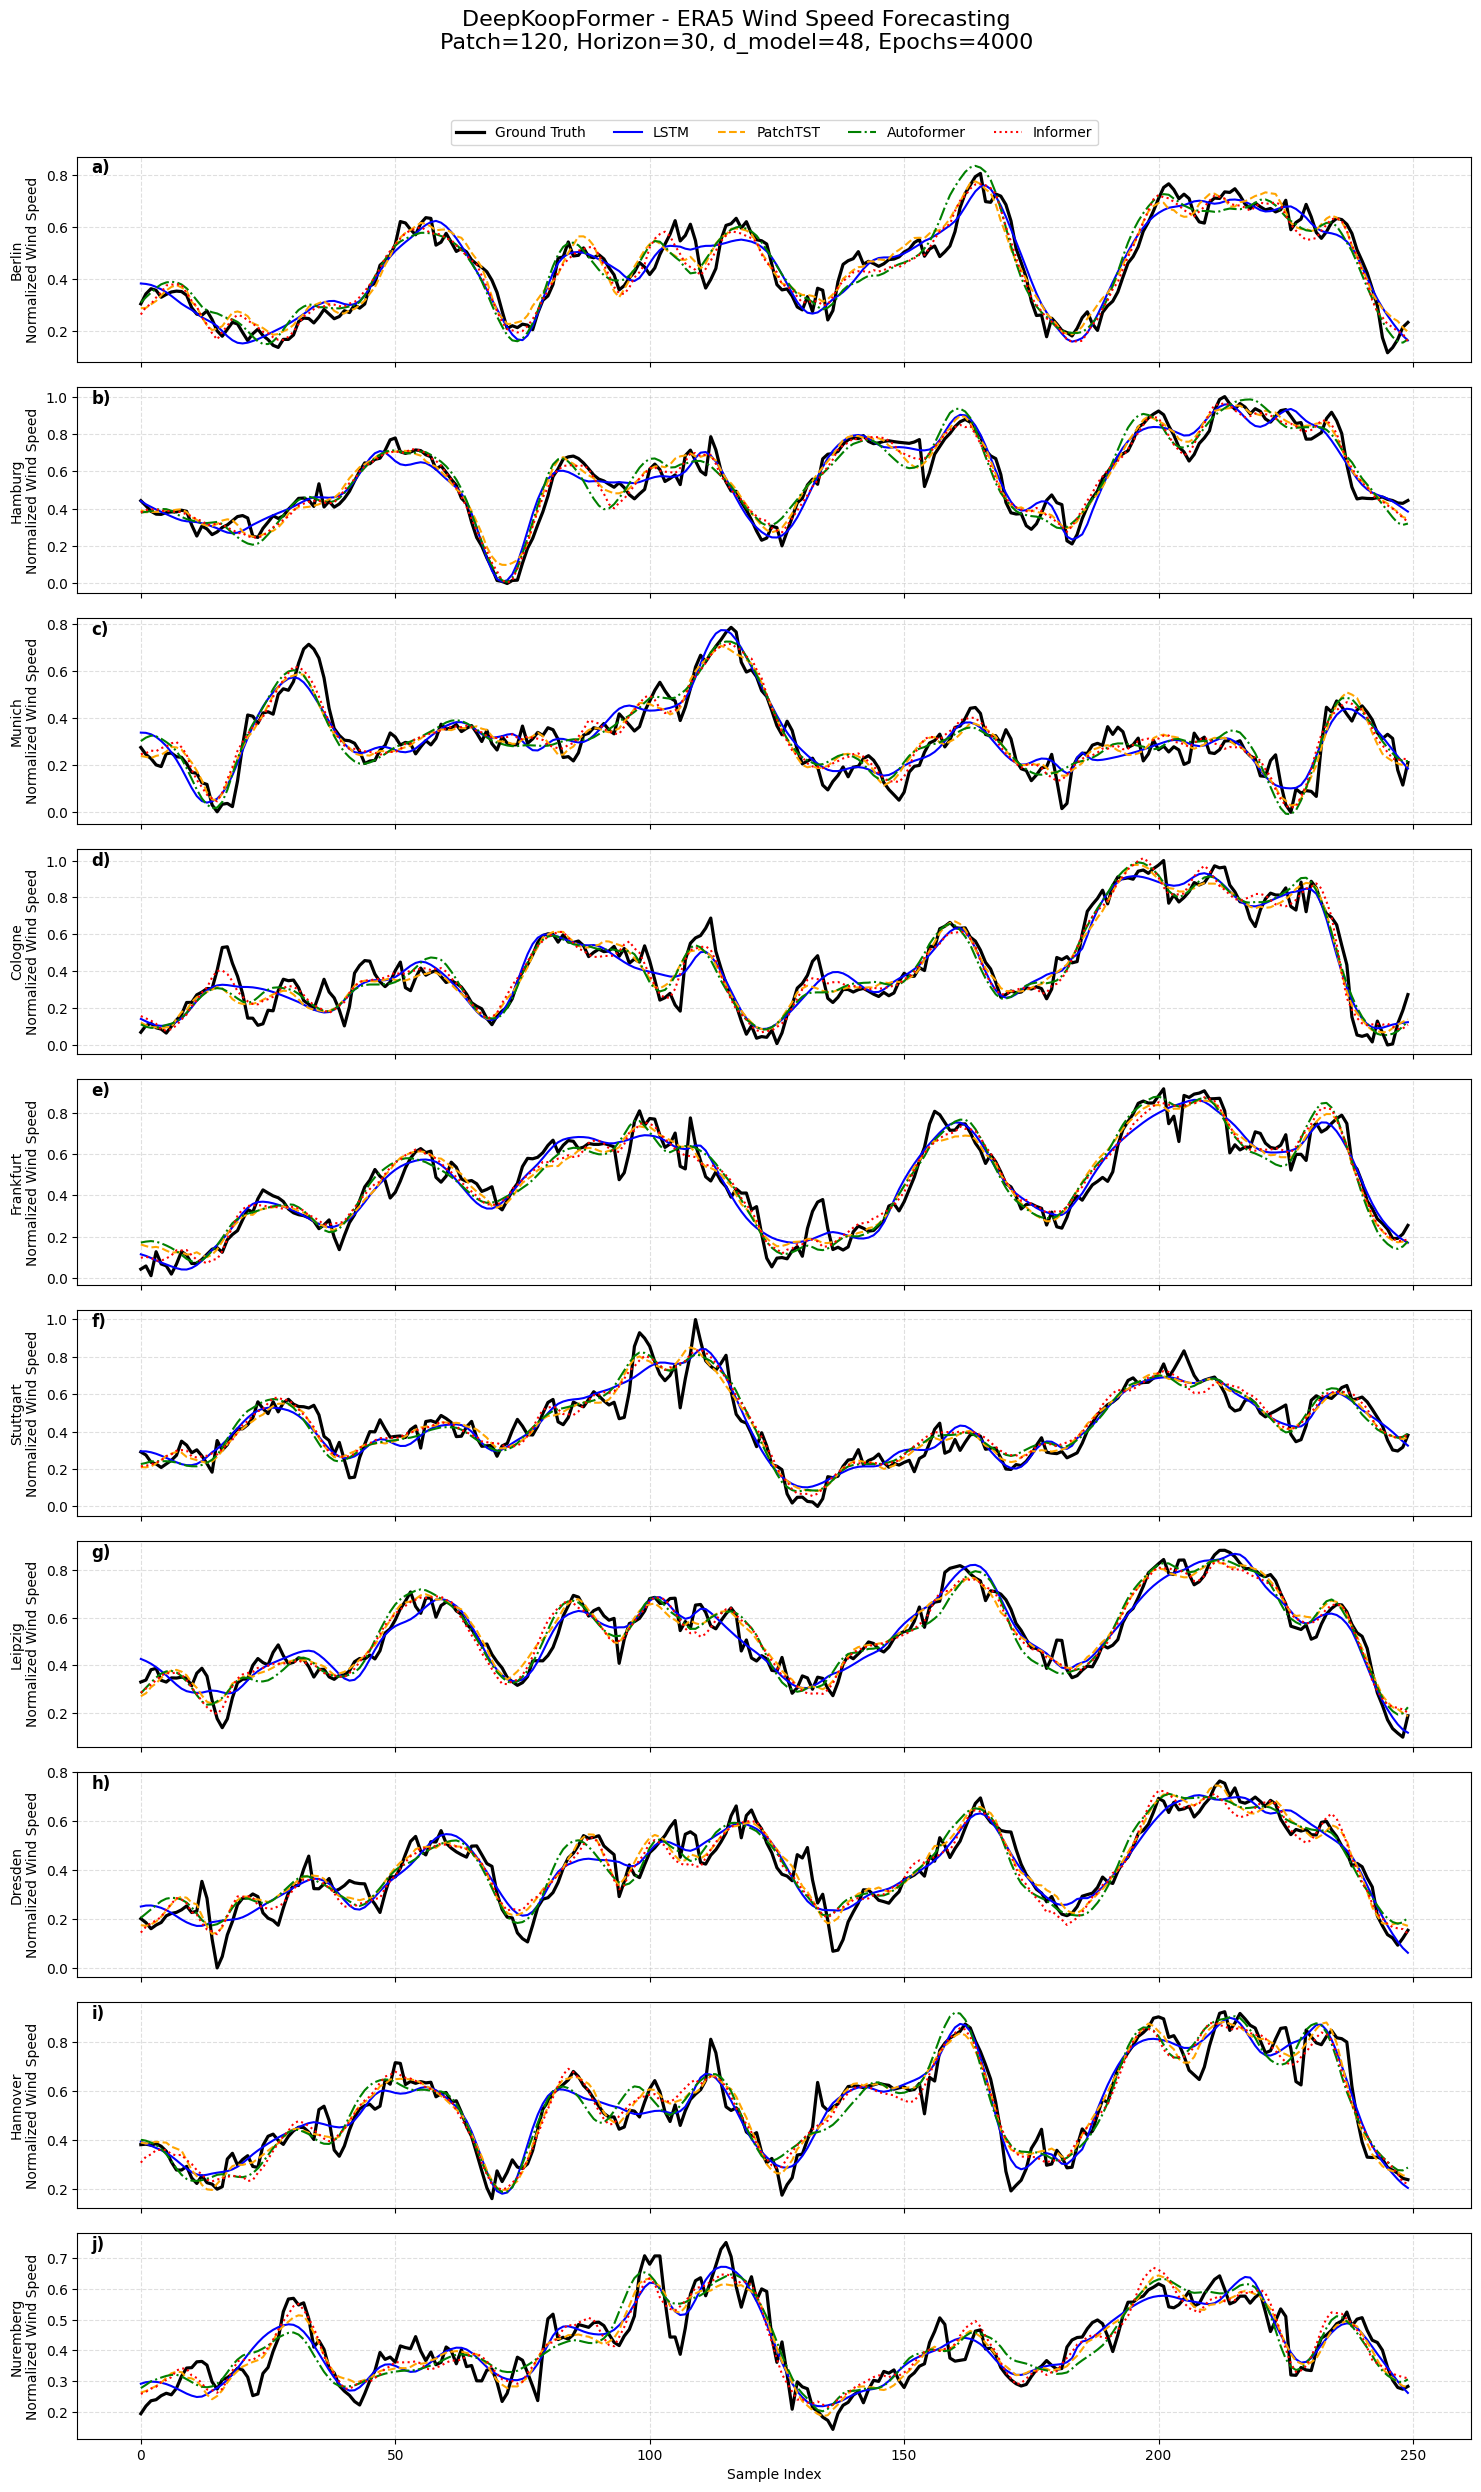


Samples: 250
Locations: 10
Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\results\era5_wind_e4000\figure7_era5_forecasting_e4000.png


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# 1. Locate local results
project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (
            p / "experiments" / "02_climate"
            / "results" / "era5_wind_e4000"
        ).is_dir()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError("Local ERA5 results directory not found")

results_dir = (
    project_root / "experiments" / "02_climate"
    / "results" / "era5_wind_e4000"
)

# 2. Figure 7 configuration
P, H, D = 120, 30, 48
model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]

# 3. Load trained checkpoints
results = {}

for name in model_names:
    path = results_dir / f"{name.lower()}_p{P}_h{H}_d{D}.pt"

    if not path.is_file():
        raise FileNotFoundError(path)

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    assert ckpt["epochs"] == 4000
    assert ckpt["patch_len"] == P
    assert ckpt["horizon"] == H
    assert ckpt["d_model"] == D
    assert ckpt["input_dim"] == 10

    results[name] = ckpt

    print(
        f"{name:<12} "
        f"MSE={ckpt['mse']:.6f} "
        f"MAE={ckpt['mae']:.6f}"
    )

# 4. Prepare Ground Truth and predictions
truth_tensor = results["LSTM"]["truth"]
N = truth_tensor.shape[0]
F = 10

assert truth_tensor.shape == (250, F * H)

location_names = results["LSTM"]["location_names"]

# Forecast step 0, following the author's plotting convention
ground_truth = (
    truth_tensor.numpy()
    .reshape(N, F, H)[:, :, 0]
)

predictions = {}

for name, ckpt in results.items():
    assert torch.allclose(
        ckpt["truth"], truth_tensor,
        atol=1e-6, rtol=1e-6
    ), f"Ground Truth mismatch: {name}"

    predictions[name] = (
        ckpt["pred"].numpy()
        .reshape(N, F, H)[:, :, 0]
    )

# 5. Plot all 10 locations
styles = {
    "LSTM": {
        "color": "blue",
        "linestyle": "-"
    },
    "PatchTST": {
        "color": "orange",
        "linestyle": "--"
    },
    "Autoformer": {
        "color": "green",
        "linestyle": "-."
    },
    "Informer": {
        "color": "red",
        "linestyle": ":"
    }
}

fig, axes = plt.subplots(
    F, 1,
    figsize=(15, 25),
    sharex=True
)

for site, ax in enumerate(axes):

    ax.plot(
        np.arange(N),
        ground_truth[:, site],
        color="black",
        linewidth=2.3,
        label="Ground Truth"
    )

    for name in model_names:
        ax.plot(
            np.arange(N),
            predictions[name][:, site],
            linewidth=1.5,
            label=name,
            **styles[name]
        )

    ax.set_ylabel(
        f"{location_names[site]}\nNormalized Wind Speed"
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.4
    )

    ax.text(
        0.01, 0.92,
        f"{chr(97 + site)})",
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold"
    )

axes[0].legend(
    ncol=5,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02)
)

axes[-1].set_xlabel("Sample Index")

fig.suptitle(
    "DeepKoopFormer - ERA5 Wind Speed Forecasting\n"
    "Patch=120, Horizon=30, d_model=48, Epochs=4000",
    fontsize=16,
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.98])

# 6. Save figure
save_path = results_dir / "figure7_era5_forecasting_e4000.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSamples:", N)
print("Locations:", F)
print("Saved:", save_path)


ERA5 Training Analysis (4000 Epochs)

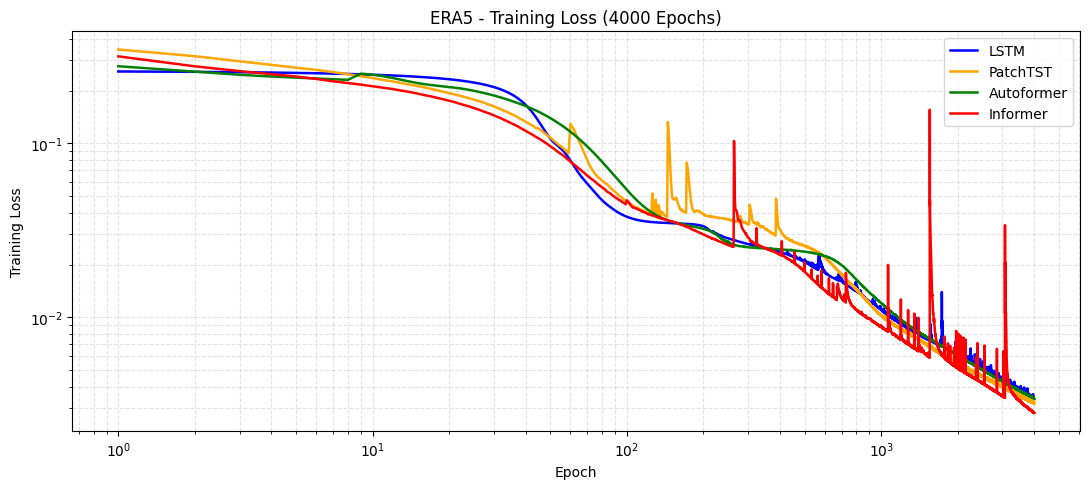

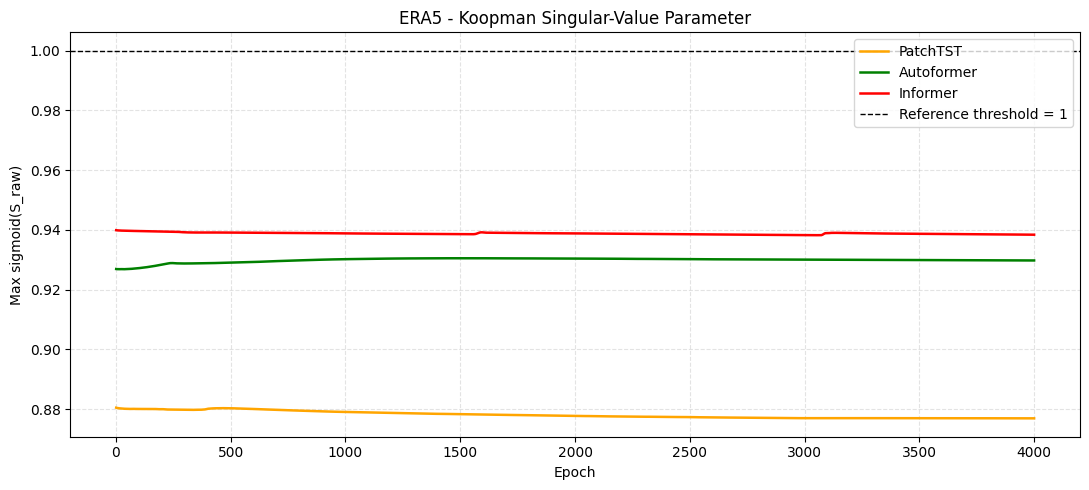

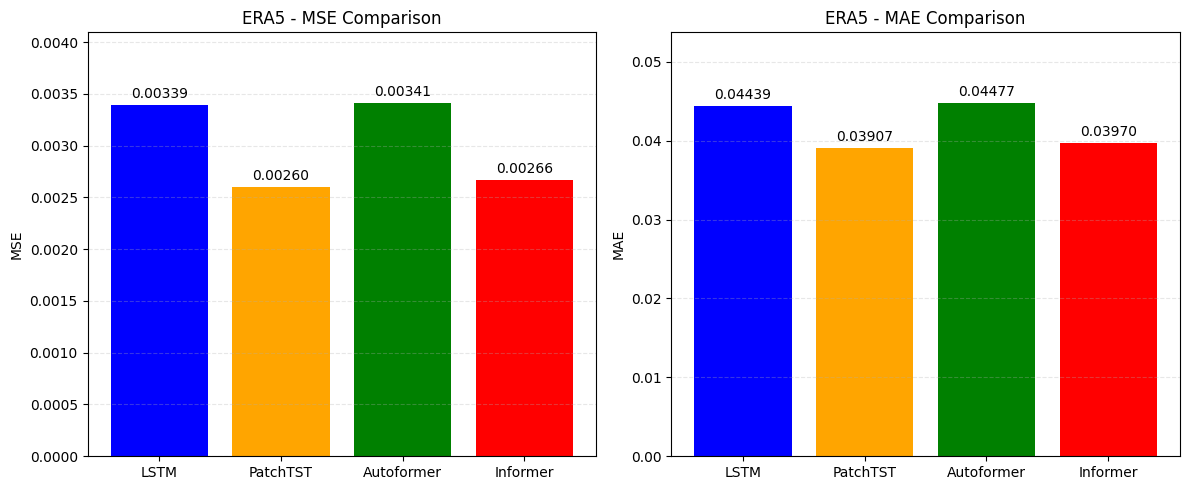


=== ERA5 MODEL COMPARISON ===
     Model      MSE      MAE
  PatchTST 0.002596 0.039073
  Informer 0.002664 0.039703
      LSTM 0.003387 0.044388
Autoformer 0.003411 0.044773


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Reuse 'results', 'results_dir' and 'model_names' from Cell 5

colors = {
    "LSTM": "blue",
    "PatchTST": "orange",
    "Autoformer": "green",
    "Informer": "red"
}

# 1. Training Loss
fig, ax = plt.subplots(figsize=(11, 5))

for name in model_names:
    loss = results[name]["loss"].numpy()
    epoch_axis = np.arange(1, len(loss) + 1)

    ax.plot(
        epoch_axis,
        loss,
        label=name,
        color=colors[name],
        linewidth=1.8
    )

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("ERA5 - Training Loss (4000 Epochs)")
ax.grid(True, which="both", linestyle="--", alpha=0.35)
ax.legend()

plt.tight_layout()
plt.savefig(
    results_dir / "era5_training_loss.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# 2. Koopman Stability
fig, ax = plt.subplots(figsize=(11, 5))

for name in ["PatchTST", "Autoformer", "Informer"]:
    eig = results[name]["eig"].numpy()

    ax.plot(
        np.arange(1, len(eig) + 1),
        eig,
        label=name,
        color=colors[name],
        linewidth=1.8
    )

ax.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference threshold = 1"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Max sigmoid(S_raw)")
ax.set_title("ERA5 - Koopman Singular-Value Parameter")
ax.grid(True, linestyle="--", alpha=0.35)
ax.legend()

plt.tight_layout()
plt.savefig(
    results_dir / "era5_koopman_stability.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# 3. MSE and MAE Comparison
metrics_df = pd.DataFrame([
    {
        "Model": name,
        "MSE": results[name]["mse"],
        "MAE": results[name]["mae"]
    }
    for name in model_names
])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric in zip(axes, ["MSE", "MAE"]):
    bars = ax.bar(
        metrics_df["Model"],
        metrics_df[metric],
        color=[colors[name] for name in model_names]
    )

    ax.bar_label(bars, fmt="%.5f", padding=3)
    ax.set_ylabel(metric)
    ax.set_title(f"ERA5 - {metric} Comparison")
    ax.set_ylim(0, metrics_df[metric].max() * 1.2)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.show()

print("\n=== ERA5 MODEL COMPARISON ===")
print(metrics_df.sort_values("MSE").to_string(index=False))
